# 1. Project links

# 2. Setup

In [49]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from modules.data_loader import load_data
from modules.mongodb_loader import get_monthly_flow

## 3. Norges Bank Currency API

Norges Bank provides an open REST API for historical exchange-rate data.
For this project, EUR/NOK and USD/NOK exchange rates are downloaded.

The API series follow the structure:

`frequency.base_currency.quote_currency.tenor`

For example:

- `B.EUR.NOK.SP` = daily EUR/NOK spot exchange rate
- `B.USD.NOK.SP` = daily USD/NOK spot exchange rate

The function below accepts currencies and a date interval and returns
the exchange rates in a tidy pandas DataFrame.

### 3.1 Imports og API-adresse

In [50]:
from io import StringIO

import pandas as pd
import requests


NB_API_URL = (
    "https://data.norges-bank.no/api/data/EXR"
)

### 3.2

In [51]:
def download_exchange_rates(
    currencies=("EUR", "USD"),
    start_date="2024-01-01",
    end_date="2024-12-31",
):
    """
    Download daily exchange rates against NOK from
    the Norges Bank open data API.

    Parameters
    ----------
    currencies : tuple or list
        Currency codes to download, e.g. ("EUR", "USD").
    start_date : str
        First date in YYYY-MM-DD format.
    end_date : str
        Last date in YYYY-MM-DD format.

    Returns
    -------
    pd.DataFrame
        DataFrame with date, currency and NOK exchange rate.
    """

    frames = []

    for currency in currencies:

        # Norges Bank series key:
        # B = business-day frequency
        # currency = base currency
        # NOK = quote currency
        # SP = spot rate
        series_key = (
            f"B.{currency}.NOK.SP"
        )

        url = (
            f"{NB_API_URL}/{series_key}"
        )

        params = {
            "format": "csv",
            "startPeriod": start_date,
            "endPeriod": end_date,
            "locale": "en",
        }

        response = requests.get(
            url,
            params=params,
            timeout=60,
        )

        response.raise_for_status()

        # Read the CSV response.
        # sep=None lets pandas detect the delimiter.
        df = pd.read_csv(
            StringIO(response.text),
            sep=None,
            engine="python",
        )

        # Standardise column names.
        df.columns = [
            column.strip().upper()
            for column in df.columns
        ]

        # Check that expected API fields are present.
        required_columns = {
            "TIME_PERIOD",
            "OBS_VALUE",
        }

        if not required_columns.issubset(
            df.columns
        ):
            raise ValueError(
                "Unexpected Norges Bank API response. "
                f"Columns returned: {df.columns.tolist()}"
            )

        exchange_rate = df[
            [
                "TIME_PERIOD",
                "OBS_VALUE",
            ]
        ].copy()

        exchange_rate.columns = [
            "date",
            "exchange_rate",
        ]

        exchange_rate["date"] = (
            pd.to_datetime(
                exchange_rate["date"]
            )
        )

        exchange_rate["exchange_rate"] = (
            pd.to_numeric(
                exchange_rate["exchange_rate"],
                errors="coerce",
            )
        )

        exchange_rate["currency"] = (
            currency
        )

        frames.append(
            exchange_rate
        )

    rates = pd.concat(
        frames,
        ignore_index=True,
    )

    return (
        rates
        .sort_values(
            ["date", "currency"]
        )
        .reset_index(drop=True)
    )

### 3.3 

In [52]:
exchange_rates = download_exchange_rates(
    currencies=["EUR", "USD"],
    start_date="2024-01-01",
    end_date="2024-12-31",
)

display(
    exchange_rates.head(10)
)

print(
    exchange_rates.groupby(
        "currency"
    ).size()
)

,date,exchange_rate,currency
0,2024-01-02,11.2815,EUR
1,2024-01-02,10.2971,USD
2,2024-01-03,11.3200,EUR
3,2024-01-03,10.3672,USD
4,2024-01-04,11.2845,EUR
5,2024-01-04,10.3027,USD
6,2024-01-05,11.3090,EUR
7,2024-01-05,10.3553,USD
8,2024-01-08,11.3620,EUR
9,2024-01-08,10.3800,USD


currency
EUR    251
USD    251
dtype: int64


### 3.4

In [53]:
exchange_rates_wide = (
    exchange_rates
    .pivot(
        index="date",
        columns="currency",
        values="exchange_rate",
    )
    .rename(
        columns={
            "EUR": "eur_nok",
            "USD": "usd_nok",
        }
    )
)

display(
    exchange_rates_wide.head()
)

currency,eur_nok,usd_nok
date,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


### 3.5

<Axes: title={'center': 'EUR/NOK and USD/NOK Exchange Rates – 2024'}, xlabel='date', ylabel='NOK per unit of currency'>

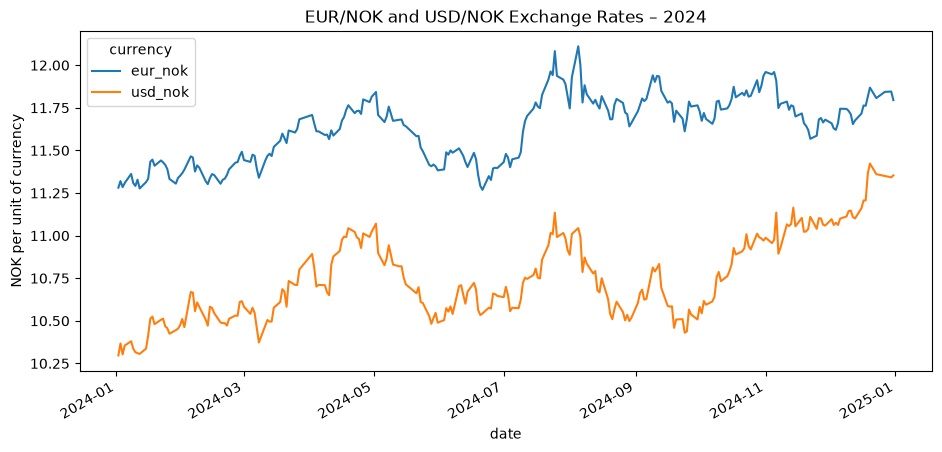

In [54]:
exchange_rates_wide.plot(
    figsize=(11, 5),
    title="EUR/NOK and USD/NOK Exchange Rates – 2024",
    ylabel="NOK per unit of currency",
)

## 4. Timezone Investigation

The project combines data from four different sources:

- NVE Magasinstatistikk
- ENTSO-E Transparency Platform
- Open-Meteo
- Norges Bank

Before combining the datasets, their time representations were investigated
to avoid shifts caused by different time zones or daylight-saving time.

This is particularly important for the hourly ENTSO-E and Open-Meteo data,
while Magasinstatistikk and Norges Bank mainly provide date-based observations.

### 4.1 Findings

| Data source | Time resolution | Time representation | Treatment |
|---|---|---|---|
| Magasinstatistikk | Weekly | Date/week based | Keep as calendar date |
| ENTSO-E | Hourly | UTC | Parse explicitly as UTC |
| Open-Meteo | Hourly | UTC in this project | Parse explicitly as UTC |
| Norges Bank | Daily | Date based | Keep as calendar date |

#### NVE Magasinstatistikk

Magasinstatistikk contains weekly observations. The dates represent
calendar weeks rather than precise timestamps, so timezone conversion
is not required.

For forecasting, the dates can therefore remain timezone-naive and
later be aggregated to monthly observations.

In [55]:
reservoir_data = load_data()

print(
    "Reservoir date dtype:",
    reservoir_data["date"].dtype,
)

print(
    reservoir_data[
        ["date", "area_type", "area_number"]
    ].head()
)

2026-11-23 09:53:56.482 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Reservoir date dtype: datetime64[us]
        date area_type  area_number
0 1995-01-08        EL            1
1 1995-01-08        EL            2
2 1995-01-08        EL            3
3 1995-01-08        EL            4
4 1995-01-08        EL            5


#### ENTSO-E

ENTSO-E API responses express timestamps in UTC. This avoids ambiguity
during changes between CET and CEST.

The MongoDB dataset used in this project therefore stores the physical
flow timestamps as `timestamp_utc`.

When the observations are loaded into pandas, the timestamps should
explicitly be parsed as timezone-aware UTC timestamps.

In [56]:
from modules.mongodb_loader import (
    get_connections,
    get_years,
    get_monthly_flow,
)

# Get one available ENTSO-E connection.
connections = get_connections()
selected_connection = connections[0]

# Use the most recent available year.
years = get_years(selected_connection)
selected_year = years[-1]

# Download one month of data as an example.
entsoe_sample = get_monthly_flow(
    connection=selected_connection,
    year=selected_year,
    months=[1],
)

print("Connection:", selected_connection)
print("Year:", selected_year)
print("Rows:", len(entsoe_sample))

print(
    "Timestamp dtype:",
    entsoe_sample["timestamp_utc"].dtype,
)

print(
    "Timezone:",
    entsoe_sample["timestamp_utc"].dt.tz,
)

display(entsoe_sample.head())

Connection: NO1-SE3
Year: 2026
Rows: 3072
Timestamp dtype: datetime64[us]
Timezone: None


,timestamp_utc,direction,quantity_mw
0,2026-01-01 01:00:00,Import,1180.429722
1,2026-01-01 01:15:00,Import,1229.822714
2,2026-01-01 01:30:00,Import,1315.924619
3,2026-01-01 01:45:00,Import,1584.195592
4,2026-01-01 02:00:00,Import,1392.061410


#### Open-Meteo

Open-Meteo allows the timezone of the returned observations to be
specified explicitly. In this project, all ERA5 requests use
`timezone="UTC"`.

The returned timestamps are therefore parsed explicitly as UTC in
pandas. This makes the Open-Meteo data directly compatible with the
UTC-based ENTSO-E timestamps and avoids ambiguity related to local
time and daylight-saving time.

In [57]:
from modules.weather_analysis import download_weather

weather_sample = download_weather(
    area_type="EL",
    area_number=3,
    start_date="2024-01-01",
    end_date="2024-01-07",
    n_locations=2,
)

print(
    "Open-Meteo timestamp dtype:",
    weather_sample["time"].dtype,
)

print(
    "Timezone:",
    weather_sample["time"].dt.tz,
)

display(weather_sample.head())

Open-Meteo timestamp dtype: datetime64[us, UTC]
Timezone: UTC


,time,avg_temperature,avg_precipitation,avg_snowfall
0,2024-01-01 00:00:00+00:00,-1.35,0.0,0.0
1,2024-01-01 01:00:00+00:00,-1.30,0.0,0.0
2,2024-01-01 02:00:00+00:00,-1.20,0.0,0.0
3,2024-01-01 03:00:00+00:00,-1.20,0.0,0.0
4,2024-01-01 04:00:00+00:00,-1.20,0.0,0.0


#### Norges Bank

Norges Bank publishes daily exchange rates on business days,
normally at approximately 16:00 CET.

The exchange-rate data used in this project are represented by
calendar date rather than an intraday timestamp. Since the data will
later be aggregated to monthly observations for forecasting, no
timezone conversion is required.

The date column is therefore kept as a timezone-naive calendar date.

In [58]:
print(
    "Norges Bank date dtype:",
    exchange_rates["date"].dtype,
)

print(
    exchange_rates[
        ["date", "currency", "exchange_rate"]
    ].head()
)

Norges Bank date dtype: datetime64[us]
        date currency  exchange_rate
0 2024-01-02      EUR        11.2815
1 2024-01-02      USD        10.2971
2 2024-01-03      EUR        11.3200
3 2024-01-03      USD        10.3672
4 2024-01-04      EUR        11.2845


### 4.2 Time Alignment Strategy

The investigation showed that timezone handling is mainly relevant for
the hourly ENTSO-E and Open-Meteo datasets.

Both sources are standardised to timezone-aware UTC timestamps before
further processing.

Magasinstatistikk and Norges Bank use calendar-based observations and
therefore do not require timezone conversion.

For forecasting, all sources will later be aggregated to monthly
observations. This makes it possible to align the datasets by month
while avoiding daylight-saving-time ambiguity in the underlying
hourly data.

## 5. Data Preparation for Forecasting

The forecasting model will use monthly observations.

Reservoir filling level is the target variable. Since Magasinstatistikk
contains weekly observations, the last available filling-level observation
in each month is used to represent the reservoir level at the end of that
month.

Weather data are aggregated as monthly mean temperature and monthly total
precipitation and snowfall. EUR/NOK and USD/NOK are represented by their
monthly mean exchange rates.

Using monthly data reduces the computational cost while preserving the
main seasonal patterns relevant for forecasting reservoir filling levels.

### 5.1 Reservoir target

In [59]:
# Select NO3 from Magasinstatistikk.
reservoir_no3 = (
    reservoir_data[
        (reservoir_data["area_type"] == "EL")
        & (reservoir_data["area_number"] == 3)
    ][["date", "fill_level"]]
    .dropna()
    .sort_values("date")
    .copy()
)

# Use the last weekly observation in each month as
# the representative month-end filling level.
reservoir_monthly = (
    reservoir_no3
    .set_index("date")
    ["fill_level"]
    .resample("ME")
    .last()
    .rename("fill_level")
    .to_frame()
)

display(reservoir_monthly.head())

print(
    "Period:",
    reservoir_monthly.index.min(),
    "to",
    reservoir_monthly.index.max(),
)

print(
    "Monthly observations:",
    len(reservoir_monthly),
)

,fill_level
date,
1995-01-31,0.508148
1995-02-28,0.369497
1995-03-31,0.236923
1995-04-30,0.107109
1995-05-31,0.185751


Period: 1995-01-31 00:00:00 to 2026-11-30 00:00:00
Monthly observations: 383


### 5.2 Weather data

In [60]:
from modules.weather_analysis import download_weather

weather_history = download_weather(
    area_type="EL",
    area_number=3,
    start_date="2020-01-01",
    end_date="2024-12-31",
    n_locations=10,
)

In [61]:
weather_monthly = (
    weather_history
    .set_index("time")
    .resample("ME")
    .agg(
        avg_temperature=(
            "avg_temperature",
            "mean",
        ),
        total_precipitation=(
            "avg_precipitation",
            "sum",
        ),
        total_snowfall=(
            "avg_snowfall",
            "sum",
        ),
    )
)

# The raw Open-Meteo observations are kept as UTC.
# After monthly aggregation, timezone information is no longer
# needed for joining with date-based NVE and Norges Bank data.
weather_monthly.index = (
    weather_monthly.index
    .tz_localize(None)
)

display(weather_monthly.head())

,avg_temperature,total_precipitation,total_snowfall
time,,,
2020-01-31,1.287849,238.34,46.480
2020-02-29,-0.664842,164.75,48.160
2020-03-31,-0.033790,130.16,37.681
2020-04-30,2.072778,134.40,45.766
2020-05-31,3.952352,98.02,22.603


### 5.3 Currency data

In [62]:
currency_monthly = (
    exchange_rates_wide
    .resample("ME")
    .mean()
)

display(currency_monthly.head())

currency,eur_nok,usd_nok
date,,
2024-01-31,11.350086,10.408255
2024-02-29,11.384286,10.546310
2024-03-31,11.512042,10.585689
2024-04-30,11.682800,10.891090
2024-05-31,11.589821,10.719858


In [63]:
exchange_rates = download_exchange_rates(
    currencies=["EUR", "USD"],
    start_date="2020-01-01",
    end_date="2024-12-31",
)

In [64]:
exchange_rates_wide = (
    exchange_rates
    .pivot(
        index="date",
        columns="currency",
        values="exchange_rate",
    )
    .rename(
        columns={
            "EUR": "eur_nok",
            "USD": "usd_nok",
        }
    )
)

currency_monthly = (
    exchange_rates_wide
    .resample("ME")
    .mean()
)

### 5.4 Slå alt sammen

In [65]:
forecast_data = (
    reservoir_monthly
    .join(
        weather_monthly,
        how="inner",
    )
    .join(
        currency_monthly,
        how="inner",
    )
)

display(forecast_data.head())

,fill_level,avg_temperature,total_precipitation,total_snowfall,eur_nok,usd_nok
date,,,,,,
2020-01-31,0.593076,1.287849,238.34,46.480,9.938423,8.953832
2020-02-29,0.501604,-0.664842,164.75,48.160,10.132700,9.291965
2020-03-31,0.334615,-0.033790,130.16,37.681,11.294314,10.220159
2020-04-30,0.263558,2.072778,134.40,45.766,11.342942,10.443505
2020-05-31,0.268268,3.952352,98.02,22.603,10.990579,10.087426


### 5.5 Kontroller manglende verdier

In [66]:
print(
    forecast_data.isna().sum()
)

fill_level             0
avg_temperature        0
total_precipitation    0
total_snowfall         0
eur_nok                0
usd_nok                0
dtype: int64


In [67]:
print(
    forecast_data.describe().round(3)
)

       fill_level  avg_temperature  total_precipitation  total_snowfall  \
count      60.000           60.000               60.000          60.000   
mean        0.609            4.409              124.824          19.165   
std         0.241            5.998               51.144          19.650   
min         0.132           -6.455               42.630           0.000   
25%         0.413           -0.068               86.705           0.371   
50%         0.685            3.031              129.690          13.296   
75%         0.817           10.672              163.260          34.361   
max         0.961           14.473              269.260          80.766   

       eur_nok  usd_nok  
count   60.000   60.000  
mean    10.808    9.786  
std      0.689    0.893  
min      9.624    8.304  
25%     10.164    8.892  
50%     10.721    9.977  
75%     11.467   10.582  
max     11.796   11.199  


In [68]:
print(
    pd.infer_freq(
        forecast_data.index
    )
)

ME


### 5.6 En enkel kontrollplot

array([<Axes: title={'center': 'Monthly Reservoir Filling Level – NO3'}, xlabel='date'>,
       <Axes: title={'center': 'Monthly Mean Temperature – NO3'}, xlabel='date'>],
      dtype=object)

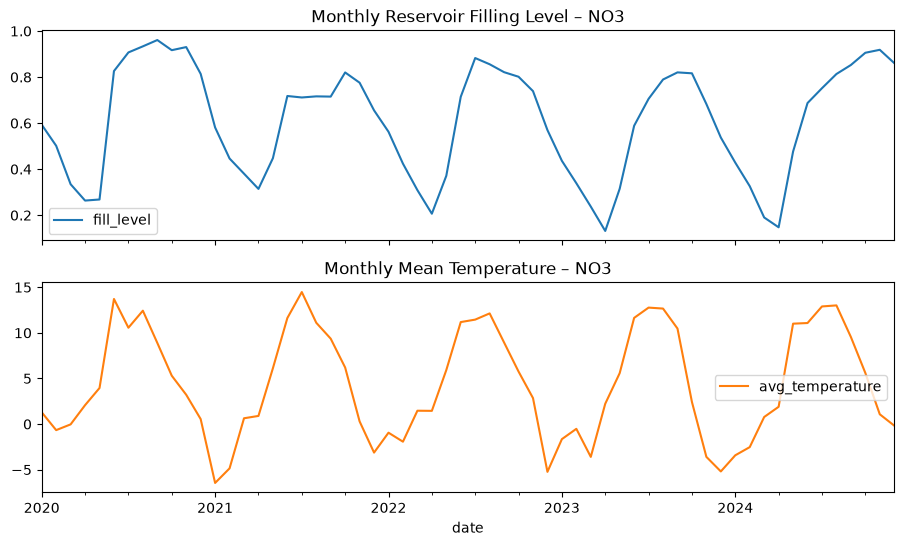

In [69]:
forecast_data[
    [
        "fill_level",
        "avg_temperature",
    ]
].plot(
    subplots=True,
    figsize=(11, 6),
    title=[
        "Monthly Reservoir Filling Level – NO3",
        "Monthly Mean Temperature – NO3",
    ],
)

## 6. River SNARIMAX Forecasting

A SNARIMAX model from the River framework is used to forecast monthly
reservoir filling levels.

Monthly resolution is used because the forecasting task concerns the
coming months and this provides a reasonable balance between seasonal
information and computational efficiency.

The function allows the model parameters, amount of historical training
data, forecast horizon and inclusion of weather and currency variables
to be changed.

The model is first evaluated using a holdout period at the end of the
available dataset. This makes it possible to compare the forecast with
actual observed filling levels.

### 6.1 Import River

In [71]:
import numpy as np
import pandas as pd

from river import time_series

### 6.2 Forecast-funksjonen

In [72]:
def backtest_snarimax(
    data,
    history_years=5,
    horizon_months=6,
    p=3,
    d=1,
    q=1,
    m=12,
    sp=1,
    sd=1,
    sq=0,
    use_weather=False,
    use_currency=False,
):
    """
    Backtest a River SNARIMAX model for monthly reservoir filling levels.

    Parameters
    ----------
    data : pd.DataFrame
        Monthly forecasting dataset.
    history_years : int
        Number of years of historical data used for training.
    horizon_months : int
        Number of months to forecast.
    p, d, q : int
        Non-seasonal SNARIMAX parameters.
    m : int
        Seasonal period. For monthly data, m=12 represents one year.
    sp, sd, sq : int
        Seasonal SNARIMAX parameters.
    use_weather : bool
        Include weather variables as exogenous predictors.
    use_currency : bool
        Include EUR/NOK and USD/NOK as exogenous predictors.

    Returns
    -------
    model
        Trained River SNARIMAX model.
    results : pd.DataFrame
        Actual and predicted filling levels for the holdout period.
    summary : dict
        MAE, RMSE and model settings.
    """

    # ---------------------------------------------------------
    # Select exogenous variables
    # ---------------------------------------------------------

    feature_columns = []

    if use_weather:
        feature_columns += [
            "avg_temperature",
            "total_precipitation",
            "total_snowfall",
        ]

    if use_currency:
        feature_columns += [
            "eur_nok",
            "usd_nok",
        ]

    required_columns = (
        ["fill_level"]
        + feature_columns
    )

    model_data = (
        data[required_columns]
        .dropna()
        .sort_index()
        .copy()
    )

    # ---------------------------------------------------------
    # Split into training and holdout periods
    # ---------------------------------------------------------

    if len(model_data) <= horizon_months:
        raise ValueError(
            "Not enough observations for the selected forecast horizon."
        )

    split_position = (
        len(model_data)
        - horizon_months
    )

    # Limit training data to the selected history length.
    history_months = history_years * 12

    training_start = max(
        0,
        split_position - history_months,
    )

    train = model_data.iloc[
        training_start:split_position
    ]

    test = model_data.iloc[
        split_position:
    ]

    if len(train) < 24:
        raise ValueError(
            "At least 24 monthly training observations are recommended."
        )

    # ---------------------------------------------------------
    # Create SNARIMAX model
    # ---------------------------------------------------------

    model = time_series.SNARIMAX(
        p=p,
        d=d,
        q=q,
        m=m,
        sp=sp,
        sd=sd,
        sq=sq,
    )

    # ---------------------------------------------------------
    # Train sequentially
    # ---------------------------------------------------------

    for _, row in train.iterrows():

        if feature_columns:
            x = (
                row[feature_columns]
                .to_dict()
            )
        else:
            x = None

        model.learn_one(
            y=row["fill_level"],
            x=x,
        )

    # ---------------------------------------------------------
    # Prepare exogenous variables for forecast period
    # ---------------------------------------------------------

    if feature_columns:
        future_x = (
            test[feature_columns]
            .to_dict(
                orient="records"
            )
        )
    else:
        future_x = None

    # ---------------------------------------------------------
    # Forecast the holdout period
    # ---------------------------------------------------------

    predictions = model.forecast(
        horizon=horizon_months,
        xs=future_x,
    )

    results = pd.DataFrame(
        {
            "actual": (
                test["fill_level"]
                .to_numpy()
            ),
            "predicted": predictions,
        },
        index=test.index,
    )

    results["error"] = (
        results["actual"]
        - results["predicted"]
    )

    # ---------------------------------------------------------
    # Evaluation metrics
    # ---------------------------------------------------------

    mae = np.mean(
        np.abs(
            results["error"]
        )
    )

    rmse = np.sqrt(
        np.mean(
            results["error"] ** 2
        )
    )

    summary = {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "training_months": len(train),
        "forecast_months": horizon_months,
        "weather": use_weather,
        "currency": use_currency,
        "p": p,
        "d": d,
        "q": q,
        "m": m,
        "sp": sp,
        "sd": sd,
        "sq": sq,
    }

    return model, results, summary

### 6.3 Første test: kun historisk fyllingsgrad

In [73]:
model_base, results_base, summary_base = (
    backtest_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=6,
        p=3,
        d=1,
        q=1,
        m=12,
        sp=1,
        sd=1,
        sq=0,
        use_weather=False,
        use_currency=False,
    )
)

print(summary_base)

display(results_base)

{'MAE': 0.08932479862082227, 'RMSE': 0.11940214440186726, 'training_months': 54, 'forecast_months': 6, 'weather': False, 'currency': False, 'p': 3, 'd': 1, 'q': 1, 'm': 12, 'sp': 1, 'sd': 1, 'sq': 0}


,actual,predicted,error
date,,,
2024-07-31,0.751678,0.796667,-0.044989
2024-08-31,0.813370,0.860785,-0.047415
2024-09-30,0.852500,0.893051,-0.040552
2024-10-31,0.905651,0.891122,0.014530
2024-11-30,0.918573,0.768846,0.149727
2024-12-31,0.860887,0.622149,0.238737


### 6.4 Plot forecast mot faktisk verdi

Text(0.5, 0, 'Month')

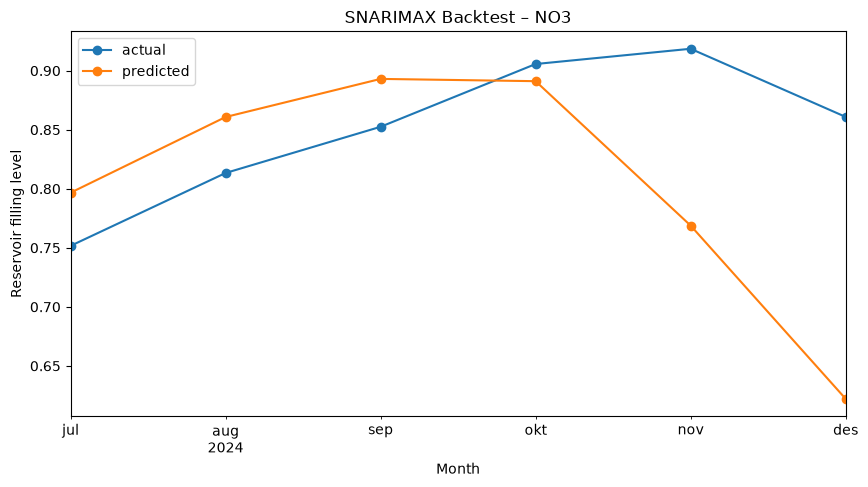

In [74]:
ax = results_base[
    ["actual", "predicted"]
].plot(
    figsize=(10, 5),
    marker="o",
    title="SNARIMAX Backtest – NO3",
)

ax.set_ylabel(
    "Reservoir filling level"
)

ax.set_xlabel(
    "Month"
)

### 6.5 Test med weather

In [75]:
model_weather, results_weather, summary_weather = (
    backtest_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=6,
        use_weather=True,
        use_currency=False,
    )
)

print(summary_weather)

{'MAE': 0.08062289122471217, 'RMSE': 0.08627720187377863, 'training_months': 54, 'forecast_months': 6, 'weather': True, 'currency': False, 'p': 3, 'd': 1, 'q': 1, 'm': 12, 'sp': 1, 'sd': 1, 'sq': 0}


### 6.6 Test med weather + currency

In [76]:
model_all, results_all, summary_all = (
    backtest_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=6,
        use_weather=True,
        use_currency=True,
    )
)

print(summary_all)

{'MAE': 0.0754556228821215, 'RMSE': 0.08004028310832456, 'training_months': 54, 'forecast_months': 6, 'weather': True, 'currency': True, 'p': 3, 'd': 1, 'q': 1, 'm': 12, 'sp': 1, 'sd': 1, 'sq': 0}


In [77]:
comparison = pd.DataFrame(
    [
        {
            "model": "Reservoir only",
            **summary_base,
        },
        {
            "model": "Reservoir + weather",
            **summary_weather,
        },
        {
            "model": "Reservoir + weather + currency",
            **summary_all,
        },
    ]
)

display(
    comparison[
        [
            "model",
            "MAE",
            "RMSE",
            "training_months",
            "forecast_months",
        ]
    ]
)

,model,MAE,RMSE,training_months,forecast_months
0,Reservoir only,0.089325,0.119402,54,6
1,Reservoir + weather,0.080623,0.086277,54,6
2,Reservoir + weather + currency,0.075456,0.080040,54,6


### 6.7 Future Forecasting

The previous experiments evaluated the model using known historical
observations. A real forecast requires predictions beyond the end of
the available dataset.

When exogenous variables are used, future values must also be provided.
Since actual future weather and exchange rates are unknown, simple and
transparent assumptions are used:

- Weather variables use historical averages for the corresponding
  calendar month.
- EUR/NOK and USD/NOK use the most recently observed exchange rate.

These assumptions make it possible to generate a multi-step forecast
without using information from the future.

In [84]:
def forecast_future_snarimax(
    data,
    history_years=5,
    horizon_months=6,
    p=3,
    d=1,
    q=1,
    m=12,
    sp=1,
    sd=1,
    sq=1,
    use_weather=True,
    use_currency=True,
):
    """
    Train a River SNARIMAX model and forecast future
    monthly reservoir filling levels.

    Future weather values are estimated using historical
    monthly averages. Future currency values use the last
    observed exchange rate.

    Returns
    -------
    forecast : pd.DataFrame
        Future predicted reservoir filling levels and
        assumed exogenous variables.
    model
        Trained River SNARIMAX model.
    """

    # ---------------------------------------------------------
    # Select exogenous features
    # ---------------------------------------------------------

    weather_columns = [
        "avg_temperature",
        "total_precipitation",
        "total_snowfall",
    ]

    currency_columns = [
        "eur_nok",
        "usd_nok",
    ]

    feature_columns = []

    if use_weather:
        feature_columns += weather_columns

    if use_currency:
        feature_columns += currency_columns

    required_columns = (
        ["fill_level"]
        + feature_columns
    )

    model_data = (
        data[required_columns]
        .dropna()
        .sort_index()
        .copy()
    )

    # ---------------------------------------------------------
    # Select training history
    # ---------------------------------------------------------

    history_months = history_years * 12

    train = model_data.tail(
        history_months
    )

    if len(train) < 24:
        raise ValueError(
            "At least 24 months of training data are required."
        )

    # ---------------------------------------------------------
    # Create model
    # ---------------------------------------------------------

    model = time_series.SNARIMAX(
        p=p,
        d=d,
        q=q,
        m=m,
        sp=sp,
        sd=sd,
        sq=sq,
    )

    # ---------------------------------------------------------
    # Train sequentially
    # ---------------------------------------------------------

    for _, row in train.iterrows():

        if feature_columns:
            x = (
                row[feature_columns]
                .to_dict()
            )
        else:
            x = None

        model.learn_one(
            y=row["fill_level"],
            x=x,
        )

    # ---------------------------------------------------------
    # Create future monthly dates
    # ---------------------------------------------------------

    last_date = train.index.max()

    future_dates = pd.date_range(
        start=(
            last_date
            + pd.offsets.MonthEnd(1)
        ),
        periods=horizon_months,
        freq="ME",
    )

    future_data = pd.DataFrame(
        index=future_dates
    )

    # ---------------------------------------------------------
    # Estimate future weather
    # ---------------------------------------------------------

    if use_weather:

        # Historical average for each calendar month.
        weather_climatology = (
            train[weather_columns]
            .groupby(
                train.index.month
            )
            .mean()
        )

        for column in weather_columns:
            future_data[column] = [
                weather_climatology.loc[
                    date.month,
                    column,
                ]
                for date in future_dates
            ]

    # ---------------------------------------------------------
    # Estimate future currency
    # ---------------------------------------------------------

    if use_currency:

        # Simple persistence assumption:
        # future exchange rate = latest observed value.
        for column in currency_columns:
            future_data[column] = (
                train[column].iloc[-1]
            )

    # ---------------------------------------------------------
    # Forecast
    # ---------------------------------------------------------

    if feature_columns:
        future_x = (
            future_data[feature_columns]
            .to_dict(
                orient="records"
            )
        )
    else:
        future_x = None

    predictions = model.forecast(
        horizon=horizon_months,
        xs=future_x,
    )

    future_data[
        "predicted_fill_level"
    ] = predictions

    return future_data, model

In [85]:
future_forecast, future_model = (
    forecast_future_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=6,
        p=3,
        d=1,
        q=1,
        m=12,
        sp=1,
        sd=1,
        sq=1,
        use_weather=True,
        use_currency=True,
    )
)

display(future_forecast)

,avg_temperature,total_precipitation,total_snowfall,eur_nok,usd_nok,predicted_fill_level
2025-01-31,-2.237575,163.874,44.3268,11.739216,11.198763,0.778742
2025-02-28,-2.100882,119.380,38.8486,11.739216,11.198763,0.686913
2025-03-31,-0.152121,109.496,33.1856,11.739216,11.198763,0.571893
2025-04-30,1.706717,93.210,32.0250,11.739216,11.198763,0.537069
2025-05-31,6.516180,81.032,9.1504,11.739216,11.198763,0.841116
2025-06-30,11.846603,101.704,0.6482,11.739216,11.198763,1.077378


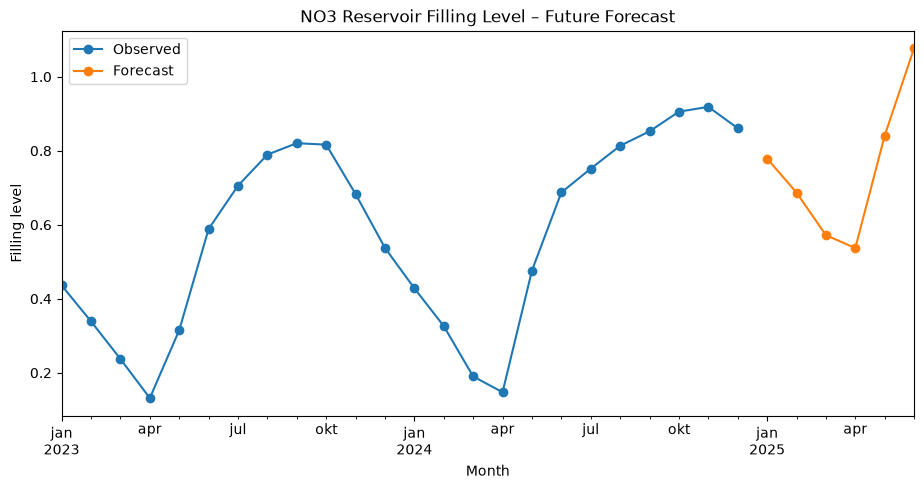

In [86]:
history_to_plot = (
    forecast_data[
        "fill_level"
    ]
    .tail(24)
)

ax = history_to_plot.plot(
    figsize=(11, 5),
    marker="o",
    label="Observed",
)

future_forecast[
    "predicted_fill_level"
].plot(
    ax=ax,
    marker="o",
    label="Forecast",
)

ax.set_title(
    "NO3 Reservoir Filling Level – Future Forecast"
)

ax.set_ylabel(
    "Filling level"
)

ax.set_xlabel(
    "Month"
)

ax.legend()

In [87]:
print(
    "Forecast range:",
    future_forecast[
        "predicted_fill_level"
    ].min(),
    "to",
    future_forecast[
        "predicted_fill_level"
    ].max(),
)

Forecast range: 0.5370690962186971 to 1.0773779077887435


### Future forecast findings

The forecast follows the expected seasonal reservoir pattern, with
declining filling levels during winter and early spring followed by
increasing levels towards summer.

However, the final unbounded SNARIMAX prediction exceeds 1.0, which is
not physically possible because reservoir filling level is restricted
to the interval [0, 1].

SNARIMAX does not inherently enforce these physical limits. For use in
the Streamlit application, the displayed forecasts are therefore
clipped to the valid interval [0, 1], while the original model output
is retained for transparency.

A more advanced alternative would be to model a transformed target,
for example using a logit transformation, but clipping is used here as
a simple and interpretable constraint.

In [ ]:
"""
future_data["predicted_fill_level_raw"] = predictions

future_data["predicted_fill_level"] = np.clip(
    predictions,
    0,
    1,
)
"""

NameError: name 'predictions' is not defined

In [89]:
future_forecast[
    "predicted_fill_level"
].plot(
    ax=ax,
    marker="o",
    label="Forecast",
)

<Axes: title={'center': 'NO3 Reservoir Filling Level – Future Forecast'}, xlabel='Month', ylabel='Filling level'>

## 7. Model Testing and Comparison

Several SNARIMAX configurations are tested to investigate how forecast
performance changes with model parameters, training-history length,
forecast horizon and the inclusion of exogenous variables.

The models are evaluated using Mean Absolute Error (MAE) and Root Mean
Squared Error (RMSE). Lower values indicate better forecasts.

The same holdout approach is used for all configurations so that the
results are directly comparable.

In [78]:
experiments = [
    {
        "name": "Simple AR",
        "p": 1,
        "d": 0,
        "q": 0,
        "sp": 1,
        "sd": 0,
        "sq": 0,
    },
    {
        "name": "Default SNARIMAX",
        "p": 3,
        "d": 1,
        "q": 1,
        "sp": 1,
        "sd": 1,
        "sq": 0,
    },
    {
        "name": "Longer AR",
        "p": 6,
        "d": 1,
        "q": 0,
        "sp": 1,
        "sd": 1,
        "sq": 0,
    },
    {
        "name": "Seasonal MA",
        "p": 3,
        "d": 1,
        "q": 1,
        "sp": 1,
        "sd": 1,
        "sq": 1,
    },
]

In [79]:
feature_settings = [
    {
        "label": "Reservoir only",
        "weather": False,
        "currency": False,
    },
    {
        "label": "Reservoir + weather",
        "weather": True,
        "currency": False,
    },
    {
        "label": "Reservoir + weather + currency",
        "weather": True,
        "currency": True,
    },
]

In [80]:
test_results = []

for experiment in experiments:
    for features in feature_settings:

        try:
            _, _, summary = backtest_snarimax(
                forecast_data,
                history_years=5,
                horizon_months=6,
                p=experiment["p"],
                d=experiment["d"],
                q=experiment["q"],
                m=12,
                sp=experiment["sp"],
                sd=experiment["sd"],
                sq=experiment["sq"],
                use_weather=features["weather"],
                use_currency=features["currency"],
            )

            test_results.append(
                {
                    "model": experiment["name"],
                    "data": features["label"],
                    "MAE": summary["MAE"],
                    "RMSE": summary["RMSE"],
                }
            )

        except Exception as error:
            print(
                experiment["name"],
                features["label"],
                "failed:",
                error,
            )

In [81]:
model_comparison = (
    pd.DataFrame(test_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(model_comparison)

,model,data,MAE,RMSE
0,Seasonal MA,Reservoir + weather + currency,0.074495,0.078628
1,Default SNARIMAX,Reservoir + weather + currency,0.075456,0.080040
2,Longer AR,Reservoir + weather + currency,0.077764,0.081147
3,Default SNARIMAX,Reservoir + weather,0.080623,0.086277
4,Seasonal MA,Reservoir + weather,0.080148,0.086800
5,Longer AR,Reservoir + weather,0.082526,0.088801
6,Default SNARIMAX,Reservoir only,0.089325,0.119402
7,Seasonal MA,Reservoir only,0.089418,0.121361
8,Longer AR,Reservoir only,0.090269,0.122336
9,Simple AR,Reservoir + weather + currency,0.257777,0.319379


In [82]:
history_results = []

for years in [3, 4, 5]:

    _, _, summary = backtest_snarimax(
        forecast_data,
        history_years=years,
        horizon_months=6,
        p=3,
        d=1,
        q=1,
        m=12,
        sp=1,
        sd=1,
        sq=0,
        use_weather=True,
        use_currency=False,
    )

    history_results.append(
        {
            "history_years": years,
            "MAE": summary["MAE"],
            "RMSE": summary["RMSE"],
        }
    )

display(
    pd.DataFrame(history_results)
)

,history_years,MAE,RMSE
0,3,0.099919,0.112221
1,4,0.085975,0.089739
2,5,0.080623,0.086277


In [83]:
horizon_results = []

for horizon in [3, 6, 9]:

    _, _, summary = backtest_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=horizon,
        p=3,
        d=1,
        q=1,
        m=12,
        sp=1,
        sd=1,
        sq=0,
        use_weather=True,
        use_currency=False,
    )

    horizon_results.append(
        {
            "horizon_months": horizon,
            "MAE": summary["MAE"],
            "RMSE": summary["RMSE"],
        }
    )

display(
    pd.DataFrame(horizon_results)
)

,horizon_months,MAE,RMSE
0,3,0.132544,0.153014
1,6,0.080623,0.086277
2,9,0.157022,0.174687


### 7.1 Model Testing Findings

Several SNARIMAX configurations were compared using MAE and RMSE on a holdout period.

The best-performing configuration was the **Seasonal MA model with both weather and currency variables**, which achieved an MAE of approximately 0.074 and an RMSE of approximately 0.079. This performed better than the reservoir-only models, indicating that the exogenous variables provided useful information for predicting reservoir filling levels.

Adding weather variables alone also improved the forecast compared with the reservoir-only baseline. Adding both weather and currency variables produced a further improvement for the strongest model configurations.

The length of the training history was also tested. Performance improved when increasing the available history from three to five years, with five years giving the lowest MAE and RMSE. This suggests that several years of historical observations are useful for capturing the seasonal behaviour of reservoir filling levels.

Forecast horizons of 3, 6 and 9 months were tested. The six-month forecast produced the lowest error in this experiment. However, these results should be interpreted carefully because each horizon is evaluated over a different set of calendar months, meaning that seasonal differences may influence the comparison.

Based on these experiments, the current preferred configuration is a Seasonal MA SNARIMAX model with five years of history, a six-month forecast horizon and weather and currency variables as exogenous inputs.

One limitation is that the backtest uses observed exogenous values during the holdout period. In a real future forecast, these values would not yet be known. A separate strategy is therefore required for generating or approximating future exogenous inputs when the model is implemented in Streamlit.

## 8. Sliding Window Correlation

A sliding-window correlation is used to investigate whether meteorological
variables are associated with reservoir filling levels over time.

The analysis allows the following parameters to be changed:

- meteorological variable
- lag between weather and reservoir filling
- rolling window length

A positive lag means that the weather variable occurs before the reservoir
observation. For example, a lag of two months compares reservoir filling
in the current month with weather conditions two months earlier.

This can help identify relationships that may be useful for forecasting.

### 8.1 Forbered data

In [90]:
correlation_data = forecast_data.copy()

# Monthly change in reservoir filling level.
correlation_data["fill_change"] = (
    correlation_data["fill_level"].diff()
)

display(
    correlation_data.head()
)

,fill_level,avg_temperature,total_precipitation,total_snowfall,eur_nok,usd_nok,fill_change
date,,,,,,,
2020-01-31,0.593076,1.287849,238.34,46.480,9.938423,8.953832,NaN
2020-02-29,0.501604,-0.664842,164.75,48.160,10.132700,9.291965,-0.091472
2020-03-31,0.334615,-0.033790,130.16,37.681,11.294314,10.220159,-0.166989
2020-04-30,0.263558,2.072778,134.40,45.766,11.342942,10.443505,-0.071057
2020-05-31,0.268268,3.952352,98.02,22.603,10.990579,10.087426,0.004710


### 8.2 Lag funksjonen

In [91]:
def sliding_window_correlation(
    data,
    weather_property="avg_temperature",
    reservoir_property="fill_level",
    lag=0,
    window=12,
):
    """
    Calculate a rolling correlation between a weather variable
    and a reservoir variable.

    Parameters
    ----------
    data : pd.DataFrame
        Monthly dataset containing reservoir and weather variables.
    weather_property : str
        Meteorological variable to analyse.
    reservoir_property : str
        Reservoir variable, e.g. fill_level or fill_change.
    lag : int
        Number of months the weather variable leads the reservoir variable.
        lag=1 means weather at t-1 is compared with reservoir at t.
    window : int
        Number of months included in each rolling correlation.

    Returns
    -------
    pd.DataFrame
        DataFrame containing the aligned variables and rolling correlation.
    """

    if weather_property not in data.columns:
        raise ValueError(
            f"Unknown weather property: {weather_property}"
        )

    if reservoir_property not in data.columns:
        raise ValueError(
            f"Unknown reservoir property: {reservoir_property}"
        )

    if window < 3:
        raise ValueError(
            "Window length must be at least 3 months."
        )

    result = data[
        [
            reservoir_property,
            weather_property,
        ]
    ].copy()

    # Positive lag means weather occurs before the
    # reservoir observation.
    result["weather_lagged"] = (
        result[weather_property]
        .shift(lag)
    )

    # Calculate rolling correlation.
    result["correlation"] = (
        result[reservoir_property]
        .rolling(window)
        .corr(
            result["weather_lagged"]
        )
    )

    return result.dropna()

### 8.3 Første test

In [92]:
corr_temperature = (
    sliding_window_correlation(
        correlation_data,
        weather_property="avg_temperature",
        reservoir_property="fill_level",
        lag=0,
        window=12,
    )
)

display(
    corr_temperature.head()
)

,fill_level,avg_temperature,weather_lagged,correlation
date,,,,
2020-12-31,0.814094,0.548804,0.548804,0.597403
2021-01-31,0.581198,-6.455457,-6.455457,0.549934
2021-02-28,0.446279,-4.857247,-4.857247,0.569702
2021-03-31,0.380436,0.635175,0.635175,0.562766
2021-04-30,0.314300,0.892306,0.892306,0.590286


Text(0.5, 0, 'Month')

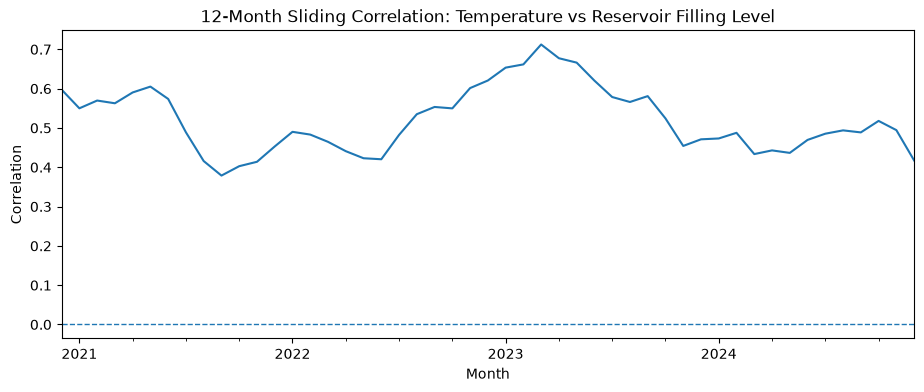

In [93]:
ax = corr_temperature[
    "correlation"
].plot(
    figsize=(11, 4),
    title=(
        "12-Month Sliding Correlation: "
        "Temperature vs Reservoir Filling Level"
    ),
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_ylabel(
    "Correlation"
)

ax.set_xlabel(
    "Month"
)

### 8.4 Test forskjellige lags

In [94]:
lag_results = []

for lag in range(0, 7):

    result = sliding_window_correlation(
        correlation_data,
        weather_property="total_precipitation",
        reservoir_property="fill_change",
        lag=lag,
        window=12,
    )

    lag_results.append(
        {
            "lag_months": lag,
            "mean_correlation": (
                result["correlation"].mean()
            ),
            "mean_absolute_correlation": (
                result["correlation"]
                .abs()
                .mean()
            ),
        }
    )

lag_comparison = pd.DataFrame(
    lag_results
)

display(lag_comparison)

,lag_months,mean_correlation,mean_absolute_correlation
0,0,0.106897,0.162598
1,1,-0.202098,0.221578
2,2,-0.288216,0.367439
3,3,-0.243532,0.257374
4,4,-0.141354,0.207750
5,5,-0.135368,0.343008
6,6,-0.173247,0.288708


### 8.5 Sammenlign weather properties

In [95]:
weather_properties = [
    "avg_temperature",
    "total_precipitation",
    "total_snowfall",
]

weather_results = []

for weather_property in weather_properties:

    result = sliding_window_correlation(
        correlation_data,
        weather_property=weather_property,
        reservoir_property="fill_change",
        lag=1,
        window=12,
    )

    weather_results.append(
        {
            "weather_property": weather_property,
            "mean_correlation": (
                result["correlation"].mean()
            ),
            "mean_absolute_correlation": (
                result["correlation"]
                .abs()
                .mean()
            ),
        }
    )

weather_comparison = pd.DataFrame(
    weather_results
).sort_values(
    "mean_absolute_correlation",
    ascending=False,
)

display(weather_comparison)

,weather_property,mean_correlation,mean_absolute_correlation
0,avg_temperature,0.442687,0.442687
2,total_snowfall,-0.368051,0.370833
1,total_precipitation,-0.202098,0.221578


### 8.6 Test window length

In [96]:
window_results = []

for window in [6, 12, 18, 24]:

    result = sliding_window_correlation(
        correlation_data,
        weather_property="total_precipitation",
        reservoir_property="fill_change",
        lag=1,
        window=window,
    )

    window_results.append(
        {
            "window_months": window,
            "mean_correlation": (
                result["correlation"].mean()
            ),
            "mean_absolute_correlation": (
                result["correlation"]
                .abs()
                .mean()
            ),
        }
    )

display(
    pd.DataFrame(window_results)
)

,window_months,mean_correlation,mean_absolute_correlation
0,6,-0.206142,0.468434
1,12,-0.202098,0.221578
2,18,-0.212008,0.212008
3,24,-0.211703,0.211703


### 8.7 Findings

The sliding-window analysis shows that the relationship between meteorological conditions and reservoir filling is not constant over time.

With a one-month lag and a 12-month rolling window, average temperature showed the strongest relationship with monthly changes in reservoir filling, with a mean correlation of approximately **0.44**. Snowfall showed a moderately strong negative relationship of approximately **−0.37**, while precipitation showed a weaker negative relationship of approximately **−0.20**.

For precipitation, different lags produced noticeably different results. A lag of approximately two months produced the strongest average absolute correlation among the tested settings. This suggests that precipitation may influence reservoir conditions with some delay rather than having an immediate relationship with filling-level changes.

The choice of rolling-window length also had a clear effect. A six-month window produced substantially stronger absolute correlations than windows of 12, 18 or 24 months. This indicates that the weather–reservoir relationship changes over time and that shorter windows may capture temporary or seasonal relationships more clearly. However, shorter windows are also based on fewer observations and may therefore be more sensitive to noise.

One possible interpretation of the positive relationship with temperature is that warmer conditions can coincide with snowmelt and increased inflow during spring. Similarly, the negative relationship with snowfall may reflect that water stored as snow does not immediately contribute to reservoir inflow.

These findings suggest that temperature, snowfall and lagged precipitation may all contain useful information for reservoir forecasting. However, the correlations should be interpreted as associations rather than causal effects.

## 9. Streamlit Structure Sketch

Before refactoring the Streamlit application, the existing and new
content was reorganised into three main functional groups:

1. **Explore** – geographical selection and descriptive data exploration.
2. **Analyse** – seasonal patterns, anomalies and relationships between datasets.
3. **Predict** – forecasting of future reservoir filling levels.

The main geographical selection is made on the Map & Data Overview page
and stored in Streamlit session state so that the selected area can be
reused across the analysis and forecasting pages.

Local controls, such as weather property, year, lag, rolling-window
length and forecasting parameters, remain on the individual pages where
they are relevant.

IND320 Energy Dashboard
│
├── Home
│
├── EXPLORE
│   │
│   ├── Map & Data Overview
│   │   ├── Interactive GeoJSON map
│   │   ├── Area type: Price / Water / Weather
│   │   ├── Area selection
│   │   ├── Time selection
│   │   └── Reservoir data overview
│   │
│   └── Energy & Markets
│       ├── Cross-border electricity flows
│       └── EUR/NOK and USD/NOK
│
├── ANALYSE
│   │
│   ├── Seasonal Analysis
│   │   ├── STL decomposition
│   │   └── Spectrogram
│   │
│   ├── Weather & Anomalies
│   │   ├── SATV / SPC
│   │   └── LOF
│   │
│   └── Weather–Reservoir Correlation
│       ├── Weather property
│       ├── Lag
│       └── Rolling-window length
│
├── PREDICT
│   │
│   └── Reservoir Forecast
│       ├── Training period
│       ├── Forecast horizon
│       ├── SNARIMAX parameters
│       ├── Exogenous variables
│       └── Animated Plotly forecast
│
└── About

### Shared and Local Controls

The selected geographical area is treated as a global application state
and will be stored using `st.session_state`.

The following selections are shared between relevant pages:

- area type
- area number / selected map region
- selected map time period

Other controls remain local because they only affect one analysis:

- SATV variable and parameters
- LOF variable and contamination
- correlation lag and rolling-window length
- SNARIMAX parameters
- exogenous-variable selection
- forecast horizon

### 9. Streamlit Structure and Design

The application is organised according to the user's analytical workflow rather than according to individual data sources.

The main navigation is divided into three functional groups: **Explore, Analyse and Predict**.

**Explore** contains the Map & Data Overview and Energy & Markets pages. The Map & Data Overview acts as the main geographical entry point to the application. Here, the user can select an area using an interactive map, choose the area type and time period, and inspect key reservoir information. The geographical selection is stored in Streamlit session state and reused on relevant pages.

**Analyse** contains Seasonal Patterns, Weather & Anomalies and Weather–Reservoir Correlation. These pages are intended for investigating historical behaviour, identifying unusual observations and exploring relationships between meteorological variables and reservoir filling levels.

**Predict** contains the Reservoir Forecast page. This separates predictive modelling from exploratory analysis and gives the forecasting interface a clear purpose. The user can select training history, forecast horizon, SNARIMAX parameters and exogenous variables.

The previous Reservoir Data and Reservoir Plots pages are combined into Map & Data Overview. This reduces the number of pages and avoids separating closely related descriptive functionality.

A consistent visual theme will be used throughout the application. Interactive plots will use Plotly and share common typography, layout and styling. The interface will use a light background with blue as the primary accent colour.

The structure follows a simple user journey:

**Explore → Analyse → Predict**

This was chosen to make the application feel like one coherent analytical dashboard rather than a collection of separate compulsory-assignment tasks.

# 10. Streamlit Implementation

# 11. AI Usage

# 12. Work Log